In [2]:
import pandas as pd

In [3]:
df= pd.read_csv(r"C:\Users\farsh\OneDrive\Desktop\Data Cleaning\archive\Raw_Dataset.csv")

In [4]:
df.head()

,Company,Company Score,Job Title,Location,Date,Salary,Skills
0,Razorpoint,3.4,Junior Data Scientist,"Manchester, England",3d,£35K (Employer est.),"Data mining, Big data, R, Data analysis skills..."
1,tower Hamlets,3.7,Assistant Data Scientist (Graduate) | R-2375,"London, England",5d,£31.00 Per Hour (Employer est.),"R, SQL, JavaScript, Python"
2,TW,4.0,Data Scientist,"Nottingham, England",30d+,£50K - £65K (Employer est.),"SQL, Maths, Data science, Python"
3,NatWest Group,4.6,Data Scientist,"Edinburgh, Scotland",2d,£41K - £54K (Glassdoor est.),"Software deployment, Data analysis skills, Sta..."
4,iwoca,3.9,Data Scientist - Ops,"London, England",7d,£60K - £90K (Employer est.),"MATLAB, R, Maths, C, Machine learning"


In [5]:
df.describe(include='all')

,Company,Company Score,Job Title,Location,Date,Salary,Skills
count,750,697.000000,750,750,750,635,742
unique,454,NaN,563,87,30,447,660
top,JPMorgan Chase & Co,NaN,Data Scientist,"London, England",30d+,£70K - £110K (Glassdoor est.),"Machine learning, Natural language processing,..."
freq,13,NaN,67,445,426,8,9
mean,NaN,3.847633,NaN,NaN,NaN,NaN,NaN
std,NaN,0.461629,NaN,NaN,NaN,NaN,NaN
min,NaN,1.700000,NaN,NaN,NaN,NaN,NaN
25%,NaN,3.600000,NaN,NaN,NaN,NaN,NaN
50%,NaN,3.900000,NaN,NaN,NaN,NaN,NaN
75%,NaN,4.100000,NaN,NaN,NaN,NaN,NaN


In [6]:
%pip install "setuptools<82"

Note: you may need to restart the kernel to use updated packages.


In [7]:
from ydata_profiling import ProfileReport

C:\Users\farsh\AppData\Local\Temp\ipykernel_17948\44057814.py:1: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


In [8]:
!pip install ipywidgets

In [9]:
#creates an exploratory report about your DataFrame df and displays it inside your notebook.
#ProfileReport(df, ...) analyzes the data in df.
#title='Summary Report' sets the report’s heading.
profile = ProfileReport(df, title= 'Summary Report')


#Display the report
#visual version of running df.info() and df.describe() together.
profile.to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 7/7 [00:00<00:00, 109.63it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [10]:
df['Salary']= df['Salary'].str.replace('£','').str.replace('K','100')

In [11]:
df.head()

,Company,Company Score,Job Title,Location,Date,Salary,Skills
0,Razorpoint,3.4,Junior Data Scientist,"Manchester, England",3d,35100 (Employer est.),"Data mining, Big data, R, Data analysis skills..."
1,tower Hamlets,3.7,Assistant Data Scientist (Graduate) | R-2375,"London, England",5d,31.00 Per Hour (Employer est.),"R, SQL, JavaScript, Python"
2,TW,4.0,Data Scientist,"Nottingham, England",30d+,50100 - 65100 (Employer est.),"SQL, Maths, Data science, Python"
3,NatWest Group,4.6,Data Scientist,"Edinburgh, Scotland",2d,41100 - 54100 (Glassdoor est.),"Software deployment, Data analysis skills, Sta..."
4,iwoca,3.9,Data Scientist - Ops,"London, England",7d,60100 - 90100 (Employer est.),"MATLAB, R, Maths, C, Machine learning"


In [12]:
#r'...'	Pass the backslashes to regex unchanged
#\(	Match an actual opening parenthesis (
#Employer est.	Match this text—although . has a special regex meaning
#\)	Match an actual closing parenthesis )

#Why put \ before parentheses? In regex, parentheses normally group patterns. Escaping them with \ means “look for the actual parenthesis character.”

df['Salary']= df['Salary'].str.replace(r'\(Employer est.\)','',regex=True)
df['Salary']= df['Salary'].str.replace(r'\(Glassdoor est.\)','',regex=True)

In [13]:
df.head()

,Company,Company Score,Job Title,Location,Date,Salary,Skills
0,Razorpoint,3.4,Junior Data Scientist,"Manchester, England",3d,35100,"Data mining, Big data, R, Data analysis skills..."
1,tower Hamlets,3.7,Assistant Data Scientist (Graduate) | R-2375,"London, England",5d,31.00 Per Hour,"R, SQL, JavaScript, Python"
2,TW,4.0,Data Scientist,"Nottingham, England",30d+,50100 - 65100,"SQL, Maths, Data science, Python"
3,NatWest Group,4.6,Data Scientist,"Edinburgh, Scotland",2d,41100 - 54100,"Software deployment, Data analysis skills, Sta..."
4,iwoca,3.9,Data Scientist - Ops,"London, England",7d,60100 - 90100,"MATLAB, R, Maths, C, Machine learning"


In [14]:
#import re loads Python’s built-in regular expression (regex) module. It lets you search, match, and replace text using patterns.
import re

In [15]:
#example: numbers = re.findall(r'\d+', salary)
#re.findall() finds all matches.
#\d     means any digit.
#+      means one or more in a row. 
#\.?	An optional decimal point
#\d*	Zero or more digits after it

#This function is intended to convert an hourly salary into a yearly salary, assuming 40 hours a week × 52 weeks = 2,080 hours.
#Simple function: 
# def function_name(input):
#    result = something_you_do_with_the_input
#    return result


def convert_to_yearly(salary):   #Defines a function named convert_to_yearly. The value you pass into it is called salary.
    if 'Per Hour' in str(salary):  #Converts the value to text and checks whether it contains "Per Hour".
        hourly_rate = re.findall(r'\d+\.?\d*', str(salary)) #Extract the number. digits before the . and it can have digits after the .

        if hourly_rate: #A nonempty list counts as True. An empty list [] counts as False.
            return float(hourly_rate[0]) * 2080    
             #hourly_rate[0] selects the first match: '25.50'.
             #float(...) converts it to the number 25.5.
             #Multiplying by 2080 gives 53040.0.
             #return sends that result back and exits the function.
    return salary  #Otherwise, keep the original value

In [16]:
df['Salary']= df['Salary'].apply(convert_to_yearly)

In [17]:
#	Converts its values to text
df['Salary']=df['Salary'].astype(str)

In [18]:
df.head()

,Company,Company Score,Job Title,Location,Date,Salary,Skills
0,Razorpoint,3.4,Junior Data Scientist,"Manchester, England",3d,35100,"Data mining, Big data, R, Data analysis skills..."
1,tower Hamlets,3.7,Assistant Data Scientist (Graduate) | R-2375,"London, England",5d,64480.0,"R, SQL, JavaScript, Python"
2,TW,4.0,Data Scientist,"Nottingham, England",30d+,50100 - 65100,"SQL, Maths, Data science, Python"
3,NatWest Group,4.6,Data Scientist,"Edinburgh, Scotland",2d,41100 - 54100,"Software deployment, Data analysis skills, Sta..."
4,iwoca,3.9,Data Scientist - Ops,"London, England",7d,60100 - 90100,"MATLAB, R, Maths, C, Machine learning"


In [19]:
#.str.split('-') splits each value wherever it finds a hyphen.
#expand=True puts the split pieces into separate columns.
#df[['salary_min', 'salary_max']] = saves those pieces into the two named columns.

df[['salary_min','salary_max']]=df['Salary'].str.split('-',expand=True)
df.head()

,Company,Company Score,Job Title,Location,Date,Salary,Skills,salary_min,salary_max
0,Razorpoint,3.4,Junior Data Scientist,"Manchester, England",3d,35100,"Data mining, Big data, R, Data analysis skills...",35100,None
1,tower Hamlets,3.7,Assistant Data Scientist (Graduate) | R-2375,"London, England",5d,64480.0,"R, SQL, JavaScript, Python",64480.0,None
2,TW,4.0,Data Scientist,"Nottingham, England",30d+,50100 - 65100,"SQL, Maths, Data science, Python",50100,65100
3,NatWest Group,4.6,Data Scientist,"Edinburgh, Scotland",2d,41100 - 54100,"Software deployment, Data analysis skills, Sta...",41100,54100
4,iwoca,3.9,Data Scientist - Ops,"London, England",7d,60100 - 90100,"MATLAB, R, Maths, C, Machine learning",60100,90100


In [20]:
#These lines remove extra spaces from the beginning and end of each value in the two salary columns:
#' 50K ' ->	'50K'

df['salary_min']=df['salary_min'].str.strip()
df['salary_max']=df['salary_max'].str.strip()


In [21]:
#pd.to_numeric(...)  converts numeric text, such as '50000', into a number.
#errors='coerce' means: “If a value cannot be converted, replace it with a missing value (NaN) instead of raising an error.”

df['salary_min']=pd.to_numeric(df['salary_min'],errors='coerce')
df['salary_max']=pd.to_numeric(df['salary_max'],errors='coerce')

In [22]:
#Location: we should split the country and city
#First need to make a string

df['Location']=df['Location'].astype(str)

In [23]:
#Split Location into two columns
df[['city','country']]=df['Location'].str.split(',',n=1,expand=True)
df.head()

,Company,Company Score,Job Title,Location,Date,Salary,Skills,salary_min,salary_max,city,country
0,Razorpoint,3.4,Junior Data Scientist,"Manchester, England",3d,35100,"Data mining, Big data, R, Data analysis skills...",35100.0,NaN,Manchester,England
1,tower Hamlets,3.7,Assistant Data Scientist (Graduate) | R-2375,"London, England",5d,64480.0,"R, SQL, JavaScript, Python",64480.0,NaN,London,England
2,TW,4.0,Data Scientist,"Nottingham, England",30d+,50100 - 65100,"SQL, Maths, Data science, Python",50100.0,65100.0,Nottingham,England
3,NatWest Group,4.6,Data Scientist,"Edinburgh, Scotland",2d,41100 - 54100,"Software deployment, Data analysis skills, Sta...",41100.0,54100.0,Edinburgh,Scotland
4,iwoca,3.9,Data Scientist - Ops,"London, England",7d,60100 - 90100,"MATLAB, R, Maths, C, Machine learning",60100.0,90100.0,London,England


In [24]:
#This line creates a separate column for each skill, using 1 if the skill is present and 0 if it isn’t:
skills_split = df['Skills'].str.get_dummies(sep=',')
skills_split

,AI,APIs,ATS,AWS,Account management,Accounting,Adobe Flash,Agile,Alteryx,Analysis skills,...,Supervising experience,Supply chain,System design,Tableau,Teaching,TensorFlow,Test-driven development,Ukrainian,Underwriting,XML
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
745,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
746,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
747,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
748,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [25]:
#pd.concat() combines pandas tables.
#[df, skills_split] lists the two tables to combine.
#axis=1 combines them side by side, adding columns.
#Remember:
#- axis=0 → stack tables vertically, adding rows.
#- axis=1 → place tables horizontally, adding columns.
#This line adds the skill columns beside the original DataFrame and stores the combined table in df_with_skills.
df_with_skills= pd.concat([df,skills_split],axis=1)
df_with_skills.head()

,Company,Company Score,Job Title,Location,Date,Salary,Skills,salary_min,salary_max,city,...,Supervising experience,Supply chain,System design,Tableau,Teaching,TensorFlow,Test-driven development,Ukrainian,Underwriting,XML
0,Razorpoint,3.4,Junior Data Scientist,"Manchester, England",3d,35100,"Data mining, Big data, R, Data analysis skills...",35100.0,NaN,Manchester,...,0,0,0,0,0,0,0,0,0,0
1,tower Hamlets,3.7,Assistant Data Scientist (Graduate) | R-2375,"London, England",5d,64480.0,"R, SQL, JavaScript, Python",64480.0,NaN,London,...,0,0,0,0,0,0,0,0,0,0
2,TW,4.0,Data Scientist,"Nottingham, England",30d+,50100 - 65100,"SQL, Maths, Data science, Python",50100.0,65100.0,Nottingham,...,0,0,0,0,0,0,0,0,0,0
3,NatWest Group,4.6,Data Scientist,"Edinburgh, Scotland",2d,41100 - 54100,"Software deployment, Data analysis skills, Sta...",41100.0,54100.0,Edinburgh,...,0,0,0,0,0,0,0,0,0,0
4,iwoca,3.9,Data Scientist - Ops,"London, England",7d,60100 - 90100,"MATLAB, R, Maths, C, Machine learning",60100.0,90100.0,London,...,0,0,0,0,0,0,0,0,0,0


In [26]:
from wordcloud import WordCloud

In [27]:
#This counts how many rows contain each skill, assuming the columns from 'AI' onward contain your skill indicators (0 and 1).
#.iloc[:, position:]	Selects all rows and columns from that position onward
#.columns.get_loc('AI')	Finds the position of the 'AI' column


#find the position of AI, then select all rows and every column from that position onward.


skill_frequencies = df_with_skills.iloc[ :, df_with_skills.columns.get_loc('AI'):].sum()

In [28]:
skill_frequencies

AI                           2
ASP.NET                      1
ATS                          1
AWS                          1
Adobe Flash                  1
                          ... 
TensorFlow                 165
Test-driven development      1
Ukrainian                    1
Underwriting                 3
XML                          1
Length: 94, dtype: int64

In [29]:
%matplotlib inline
import matplotlib.pyplot as plt

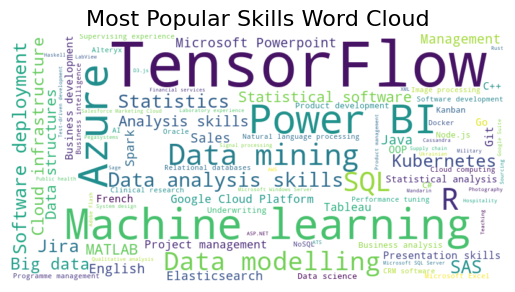

In [30]:
#WordCloud(...)	Creates a word cloud object
#width=800	Sets the image width to 800 pixels
#height=400	Sets the image height to 400 pixels
#background_color='white'	Makes the background white
#.generate_from_frequencies(skill_frequencies)	Generates the cloud using each skill and its count


wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white'
).generate_from_frequencies(skill_frequencies)

# to show


plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Most Popular Skills Word Cloud', fontsize=16)
plt.show()

In [31]:
#Selects columns from AI onward, adds up each column, and sorts the skill counts highest to lowest.
skills_columns = df_with_skills.iloc[ :, df_with_skills.columns.get_loc('AI'):].sum().sort_values(ascending = False)

In [32]:
#Keeps the first 10 skills from that sorted result.
top_10_skills = skills_columns.head(10)

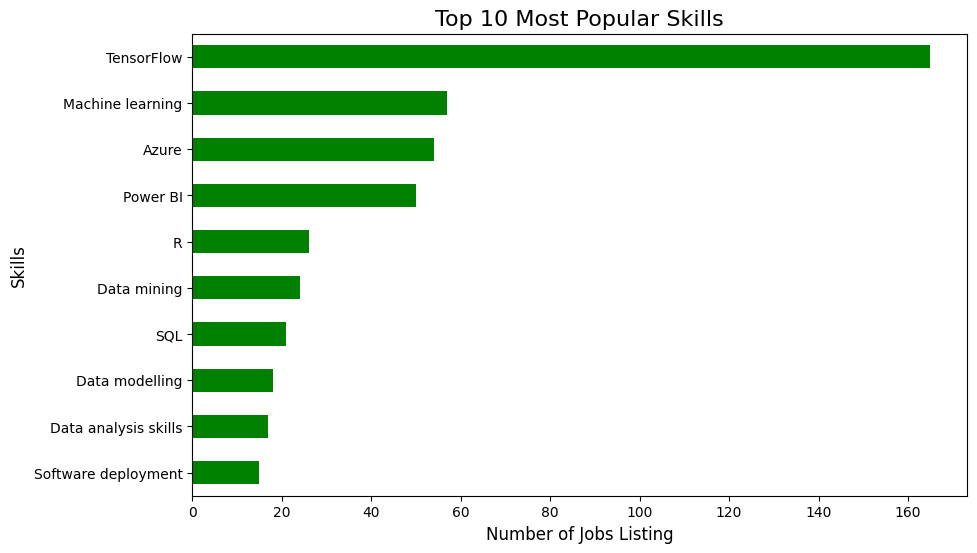

In [33]:
plt.figure(figsize=(10, 6))
top_10_skills.plot(kind = 'barh', color='green') #	Draws green horizontal bars
plt.title('Top 10 Most Popular Skills', fontsize=16)
plt.xlabel('Number of Jobs Listing', fontsize=12)
plt.ylabel('Skills', fontsize=12)
plt.gca().invert_yaxis() #invert y axis to display most popular skill at the top
plt.show()

In [40]:
#This code keeps only rows where the job title contains “Data Analyst” and saves them in da_jobs

#.str.contains('Data Analyst')	Checks whether each title contains this phrase
#case=False	Ignores uppercase/lowercase differences
#na=False	Treats missing titles as nonmatches
#df_with_skills[...]	Keeps rows where the check returns True

condition_jobs= df_with_skills['Job Title'].str.contains('Data Analyst', case=False, na=False )

matching_jobs = df_with_skills[condition_jobs]

matching_jobs



,Company,Company Score,Job Title,Location,Date,Salary,Skills,salary_min,salary_max,city,...,Supervising experience,Supply chain,System design,Tableau,Teaching,TensorFlow,Test-driven development,Ukrainian,Underwriting,XML
35,Hadrian,3.7,Commercial Data Analyst - Internship,"London, England",2d,44100 - 67100,"Relational databases, R, SQL, Statistical anal...",44100.0,67100.0,London,...,0,0,0,0,0,0,0,0,0,0
43,Windranger Labs,4.8,Data Analyst,Remote,10d,60100 - 80100,"R, Git, SQL, Machine learning, Python",60100.0,80100.0,Remote,...,0,0,0,0,0,0,0,0,0,0
48,Animoca Brands Limited,3.6,Tokenomics Data Analyst/Scientist,Remote,30d+,35100 - 60100,"Machine learning, Data science",35100.0,60100.0,Remote,...,0,0,0,0,0,0,0,0,0,0
53,Razorpoint,4.4,Junior Data Analyst,"London, England",20d,FCFA 102100,"TensorFlow, Azure, R, Google Cloud Platform, T...",NaN,NaN,London,...,0,0,0,0,0,1,0,0,0,0
67,Creditsafe,3.2,Data Analyst,"Cardiff, Wales",4d,67100,"Spark, R, Data analysis skills, NoSQL, Git",67100.0,NaN,Cardiff,...,0,0,0,0,0,0,0,0,0,0
129,Bannatyne,3.9,Data Analyst,"Darlington, North East England, England",11d,39100 - 61100,"Power BI, Azure, Big data, Spark, Tableau",39100.0,61100.0,Darlington,...,0,0,0,0,0,0,0,0,0,0
132,Global 4 Communications Limited,3.8,Data Analyst,"Horsham, England",30d+,80100 - 83100,"R, SQL, Statistical analysis, Maths, Machine l...",80100.0,83100.0,Horsham,...,0,0,0,0,0,0,0,0,0,0
148,Diamond Light Source,3.8,Data Analyst Scientist - Diamond Light Source ...,"Didcot, England",8d,55100,"Azure, R, Data analysis skills, Git, Google Cl...",55100.0,NaN,Didcot,...,0,0,0,0,0,0,0,0,0,0
159,TW,3.3,Lead Data Analyst,"Birmingham, England",30d+,74100 - 120100,"Azure, Management, R, Microsoft SQL Server, NoSQL",74100.0,120100.0,Birmingham,...,0,0,0,0,0,0,0,0,0,0
181,InPost UK,3.8,Big Data Analyst,"London, England",9d,51100 - 90100,"Machine learning, Data science, Python",51100.0,90100.0,London,...,0,0,0,0,0,0,0,0,0,0


In [41]:
matching_skills=matching_jobs.iloc[:,matching_jobs.columns.get_loc('AI'):].sum().sort_values(ascending=False)

matching_skills

Azure                      2
Machine learning           2
R                          2
TensorFlow                 2
Power BI                   1
                          ..
Teaching                   0
Test-driven development    0
Ukrainian                  0
Underwriting               0
XML                        0
Length: 94, dtype: int64

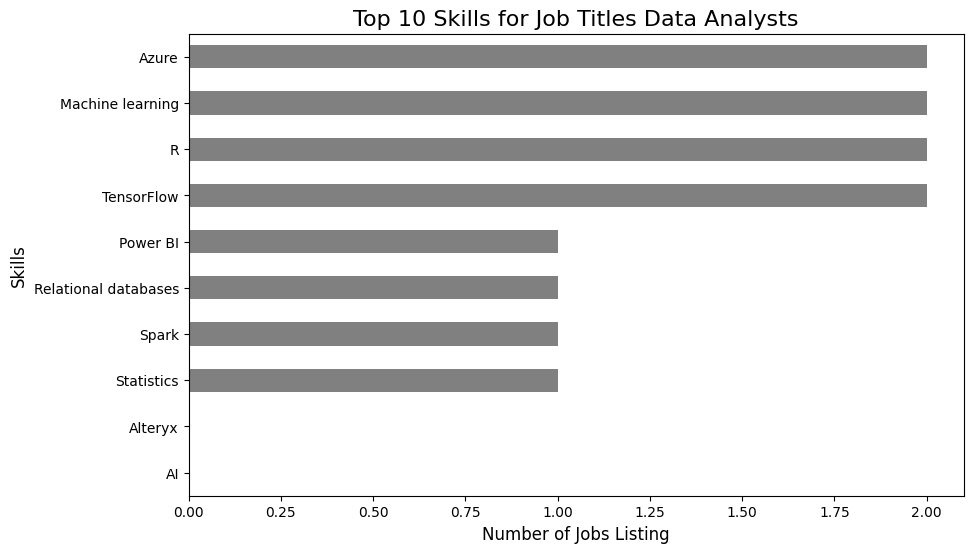

In [45]:
top_10_da_skills = matching_skills.head(10)

plt.figure(figsize=(10, 6))
top_10_da_skills.plot(kind = 'barh', color='grey') #	Draws green horizontal bars
plt.title('Top 10 Skills for Job Titles Data Analysts', fontsize=16)
plt.xlabel('Number of Jobs Listing', fontsize=12)
plt.ylabel('Skills', fontsize=12)
plt.gca().invert_yaxis() #invert y axis to display most popular skill at the top
plt.show()